# A medallion pipeline on GH Archive with PySpark, and the upstream change it caught

**Ashhar Hussain** · ORCID [0009-0009-1568-9852](https://orcid.org/0009-0009-1568-9852)

[GH Archive](https://www.gharchive.org/) publishes every public GitHub event as hourly gzipped JSON. This notebook builds a small lakehouse on it with PySpark: raw files → **bronze** (typed, partitioned Parquet) → **silver** (deduplicated, validated, with a quarantine) → **gold** (analytics tables). Loads are incremental and idempotent, and every batch is checked against a **data contract** learned from earlier data before anything is published.

The contract is not hypothetical. Comparing the same hours of 1 November 2024 and 1 November 2026, the public event stream changed underneath any pipeline built on it: volume fell by almost two orders of magnitude, whole event types disappeared and the pull-request payload was cut to a handful of fields. A pipeline without checks would keep publishing "merge rates" and "commit counts" computed from fields that no longer exist.

**Questions**

1. Can a bronze/silver/gold pipeline be built so that re-running a batch never duplicates data?
2. Which contract checks catch the 2024 → 2026 change, and which gold tables must be held back?
3. What do the classic Spark optimisations (columnar storage, partition pruning, broadcast joins) buy on a laptop-sized cluster, and how does Spark compare with DuckDB and Polars on the same query?

**Run.** Any runtime with Java 17+ (Colab has it), about 10 minutes on 2 CPU cores; downloads about 0.8 GB.

In [1]:
import os, sys, json, time, gzip, shutil, glob, urllib.request, subprocess
from pathlib import Path
from datetime import datetime, timedelta
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark", "polars", "duckdb"], check=True)

os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import StructType, StructField, StringType, LongType, BooleanType
import duckdb, polars as pl

ROOT = Path("lake"); RAW = Path("data/raw"); OUT = Path("outputs"); FIG = OUT / "figures"
for d in (RAW, FIG):
    d.mkdir(parents=True, exist_ok=True)
for layer in ("bronze", "silver", "gold", "quarantine", "_state"):
    (ROOT / layer).mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.master("local[*]").appName("gharchive-lakehouse")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.sql.sources.partitionOverwriteMode", "dynamic")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cores", spark.sparkContext.defaultParallelism)

# two batches: the same eight hours, two years apart
BATCH_2024 = [datetime(2024, 11, 1, h) for h in range(8, 16)]
BATCH_2026 = [datetime(2026, 11, 1, h) for h in range(8, 16)]


def fetch(hours):
    paths = []
    for t in hours:
        name = f"{t:%Y-%m-%d}-{t.hour}.json.gz"
        p = RAW / name
        if not p.exists():  # the archive rejects urllib's default user agent, so name the client
            req = urllib.request.Request(f"https://data.gharchive.org/{name}", headers={"User-Agent": "gharchive-lakehouse-notebook/1.0"})
            with urllib.request.urlopen(req, timeout=300) as r, open(p, "wb") as f:
                shutil.copyfileobj(r, f)
        paths.append(p)
    return paths


t0 = time.time()
files_2024, files_2026 = fetch(BATCH_2024), fetch(BATCH_2026)
mb = lambda ps: sum(p.stat().st_size for p in ps) / 2**20
print(f"downloaded in {time.time() - t0:.0f} s: 2024 batch {mb(files_2024):.0f} MB, 2026 batch {mb(files_2026):.0f} MB (gzip)")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 03:50:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0 | cores 2
downloaded in 0 s: 2024 batch 786 MB, 2026 batch 43 MB (gzip)


## Bronze: raw JSON to typed, partitioned Parquet

An explicit schema keeps parsing fast and makes the expected shape part of the code. Malformed lines land in `_corrupt_record` instead of failing the job. Partition columns `dt` and `hr` come from the file name, and every row keeps its source file and ingestion time for lineage.

In [2]:
SCHEMA = StructType([
    StructField("id", StringType()), StructField("type", StringType()),
    StructField("actor", StructType([StructField("id", LongType()), StructField("login", StringType())])),
    StructField("repo", StructType([StructField("id", LongType()), StructField("name", StringType())])),
    StructField("org", StructType([StructField("login", StringType())])),
    StructField("public", BooleanType()), StructField("created_at", StringType()),
    StructField("payload", StructType([
        StructField("action", StringType()), StructField("size", LongType()), StructField("distinct_size", LongType()),
        StructField("ref_type", StringType()),
        StructField("pull_request", StructType([StructField("merged", BooleanType()), StructField("additions", LongType()),
                                                StructField("deletions", LongType()), StructField("changed_files", LongType())])),
    ])),
    StructField("_corrupt_record", StringType()),
])


def to_bronze(paths):
    df = (spark.read.schema(SCHEMA).option("mode", "PERMISSIVE").option("columnNameOfCorruptRecord", "_corrupt_record")
          .json([str(p) for p in paths])
          .withColumn("_source_file", F.element_at(F.split(F.input_file_name(), "/"), -1))
          .withColumn("_ingested_at", F.current_timestamp()))
    parts = F.regexp_extract("_source_file", r"(\d{4}-\d{2}-\d{2})-(\d{1,2})\.json\.gz", 1)
    hr = F.regexp_extract("_source_file", r"(\d{4}-\d{2}-\d{2})-(\d{1,2})\.json\.gz", 2).cast("int")
    df = df.withColumn("dt", parts).withColumn("hr", hr)
    df.write.mode("overwrite").partitionBy("dt", "hr").parquet(str(ROOT / "bronze"))  # dynamic overwrite: only these partitions
    return df


t0 = time.time()
to_bronze(files_2024)
bronze_s = time.time() - t0
bronze = spark.read.parquet(str(ROOT / "bronze")).filter("dt = '2024-11-01'")  # this batch only, even if later batches exist
n_bronze = bronze.count()
pq_mb = sum(f.stat().st_size for f in (ROOT / "bronze" / "dt=2024-11-01").rglob("*.parquet")) / 2**20
print(f"bronze (2024 batch): {n_bronze:,} events in {bronze_s:.0f} s; {mb(files_2024):.0f} MB gzip JSON -> {pq_mb:.0f} MB Parquet "
      f"for the selected columns; corrupt lines: {bronze.filter(F.col('_corrupt_record').isNotNull()).count()}")

bronze (2024 batch): 1,870,675 events in 23 s; 786 MB gzip JSON -> 67 MB Parquet for the selected columns; corrupt lines: 0


## Silver: deduplicate, validate, quarantine

Rules: required fields present, `created_at` within the hour of its file (±1 h), event type known, one row per event id. Rows that break a rule go to `quarantine` with the reason, so nothing disappears silently.

In [3]:
KNOWN_TYPES = ["PushEvent", "CreateEvent", "DeleteEvent", "PullRequestEvent", "PullRequestReviewEvent",
               "PullRequestReviewCommentEvent", "IssuesEvent", "IssueCommentEvent", "WatchEvent", "ForkEvent",
               "ReleaseEvent", "MemberEvent", "PublicEvent", "GollumEvent", "CommitCommentEvent"]


QSCHEMA = StructType([StructField("id", StringType()), StructField("type", StringType()), StructField("created_at", StringType()),
                      StructField("reject_reason", StringType()), StructField("_source_file", StringType()),
                      StructField("dt", StringType()), StructField("hr", LongType())])


def read_quarantine():  # explicit schema, so an empty quarantine (no bad rows yet) still reads as an empty table
    return spark.read.schema(QSCHEMA).parquet(str(ROOT / "quarantine"))


def to_silver(dts_hrs):
    cond = F.lit(False)
    for dt, hr in dts_hrs:
        cond = cond | ((F.col("dt") == dt) & (F.col("hr") == hr))
    b = spark.read.parquet(str(ROOT / "bronze")).filter(cond)
    ts = F.to_timestamp("created_at")
    part_start = F.to_timestamp(F.concat_ws(" ", "dt", F.format_string("%02d:00:00", "hr")))
    b = b.withColumn("event_ts", ts).withColumn(
        "reject_reason",
        F.when(F.col("_corrupt_record").isNotNull(), "corrupt")
         .when(F.col("id").isNull() | F.col("type").isNull() | F.col("actor.id").isNull() | F.col("repo.id").isNull(), "missing_required")
         .when(ts.isNull() | (F.abs(F.unix_timestamp(ts) - F.unix_timestamp(part_start) - 1800) > 5400), "timestamp_out_of_window")
         .when(~F.col("type").isin(KNOWN_TYPES), "unknown_type"))
    bad = b.filter(F.col("reject_reason").isNotNull())
    good = b.filter(F.col("reject_reason").isNull())
    w = Window.partitionBy("id").orderBy(F.col("_ingested_at").desc())
    good = good.withColumn("_rn", F.row_number().over(w)).filter("_rn = 1").drop("_rn")
    silver = good.select(
        F.col("id").cast("long").alias("event_id"), "type", "event_ts", "dt", "hr",
        F.col("actor.id").alias("actor_id"), F.col("actor.login").alias("actor_login"),
        F.col("actor.login").endswith("[bot]").alias("is_bot"),
        F.col("repo.id").alias("repo_id"), F.col("repo.name").alias("repo_name"), F.col("org.login").alias("org_login"),
        F.col("payload.action").alias("action"), F.col("payload.size").alias("push_commits"),
        F.col("payload.ref_type").alias("ref_type"), F.col("payload.pull_request.merged").alias("pr_merged"),
        F.col("payload.pull_request.additions").alias("pr_additions"), F.col("payload.pull_request.deletions").alias("pr_deletions"))
    silver.write.mode("overwrite").partitionBy("dt", "hr").parquet(str(ROOT / "silver"))
    bad.select("id", "type", "created_at", "dt", "hr", "reject_reason", "_source_file").write.mode("overwrite") \
       .partitionBy("dt", "hr").parquet(str(ROOT / "quarantine"))
    return silver, bad


parts_2024 = [(f"{t:%Y-%m-%d}", t.hour) for t in BATCH_2024]
t0 = time.time()
to_silver(parts_2024)
silver = spark.read.parquet(str(ROOT / "silver")).filter("dt = '2024-11-01'")
quar = read_quarantine().filter("dt = '2024-11-01'")
n_silver, n_quar = silver.count(), quar.count()
print(f"silver: {n_silver:,} events ({n_bronze - n_silver - n_quar:,} duplicates removed), quarantine: {n_quar:,} rows, {time.time() - t0:.0f} s")
display(quar.groupBy("reject_reason").count().toPandas())

silver: 1,870,675 events (0 duplicates removed), quarantine: 0 rows, 16 s


,reject_reason,count


## Gold: analytics tables

* `hourly_activity`: events, distinct actors and repos per hour and type
* `repo_activity`: stars, forks, pull requests opened and merged, pushes and commits per repository and day
* `bot_share`: share of events from bot accounts by type

In [4]:
GOLD_TABLES = ("hourly_activity", "repo_activity", "bot_share")


def to_gold(dts, tables=GOLD_TABLES):
    """Rebuild the given gold tables for the given dates only (dynamic partition overwrite)."""
    s = spark.read.parquet(str(ROOT / "silver")).filter(F.col("dt").isin(list(dts)))
    hourly = s.groupBy("dt", "hr", "type").agg(F.count("*").alias("events"), F.countDistinct("actor_id").alias("actors"),
                                               F.countDistinct("repo_id").alias("repos"))
    repo = s.groupBy("dt", "repo_name").agg(
        F.sum(F.when(F.col("type") == "WatchEvent", 1).otherwise(0)).alias("stars"),
        F.sum(F.when(F.col("type") == "ForkEvent", 1).otherwise(0)).alias("forks"),
        F.sum(F.when((F.col("type") == "PullRequestEvent") & (F.col("action") == "opened"), 1).otherwise(0)).alias("prs_opened"),
        F.sum(F.when((F.col("type") == "PullRequestEvent") & (F.col("action") == "closed") & F.col("pr_merged"), 1).otherwise(0)).alias("prs_merged"),
        F.sum(F.when(F.col("type") == "PushEvent", 1).otherwise(0)).alias("pushes"),
        F.sum(F.coalesce("push_commits", F.lit(0))).alias("commits"))
    bots = s.groupBy("dt", "type").agg(F.avg(F.col("is_bot").cast("double")).alias("bot_share"), F.count("*").alias("events"))
    for name, df in (("hourly_activity", hourly), ("repo_activity", repo), ("bot_share", bots)):
        if name in tables:
            df.write.mode("overwrite").partitionBy("dt").parquet(str(ROOT / "gold" / name))


t0 = time.time()
to_gold(["2024-11-01"])
print(f"gold built in {time.time() - t0:.0f} s")
g_repo = spark.read.parquet(str(ROOT / "gold" / "repo_activity"))
display(g_repo.filter("dt = '2024-11-01'").orderBy(F.desc("stars")).limit(10).toPandas())

gold built in 6 s


,repo_name,stars,forks,prs_opened,prs_merged,pushes,commits,dt
0,doanthienminh1083/ShadowTool,1075,0,0,0,0,0,2024-11-01
1,doanthienminh1083/BlazingTool,1073,0,0,0,0,0,2024-11-01
2,LuksMB/IDA-Pro-Keygen-2024,1012,0,0,0,0,0,2024-11-01
3,LuksMB/IDM-Activation-Script-2024,1002,0,0,0,0,0,2024-11-01
4,feelps-1/YoutubePlaylistDownloader-2024-,999,0,0,0,0,0,2024-11-01
5,EduardaSantosdS/Sony-Vegas-Pro-2024,991,0,0,0,0,0,2024-11-01
6,EduardaSantosdS/Canva-Pro-2024,990,0,0,0,0,0,2024-11-01
7,GauravSakariya99/Xbox-Game-Pass-Activator-Free...,985,0,0,0,0,0,2024-11-01
8,hwidspoofer1/HWID-Spoofer-and-Cleaner-2024,975,0,0,0,0,0,2024-11-01
9,JunaidYousafzai/PhotoDiva-Pro-free-2024,973,0,0,0,0,0,2024-11-01


## Incremental and idempotent loads

A small state file records which partitions each layer has processed. Re-running a batch rewrites exactly its own partitions (dynamic partition overwrite), so counts do not change. The check below re-runs the 2024 batch through bronze and silver and compares counts.

In [5]:
STATE = ROOT / "_state" / "processed.json"


def mark(layer, parts):
    st = json.loads(STATE.read_text()) if STATE.exists() else {}
    st.setdefault(layer, [])
    st[layer] = sorted(set(map(tuple, st[layer])) | set(parts))
    STATE.write_text(json.dumps(st, indent=1))


mark("bronze", parts_2024); mark("silver", parts_2024)
count24 = lambda layer: spark.read.parquet(str(ROOT / layer)).filter("dt = '2024-11-01'").count()
before = (count24("bronze"), count24("silver"))
to_bronze(files_2024); to_silver(parts_2024)
after = (count24("bronze"), count24("silver"))
print(f"re-run of the same batch: bronze {before[0]:,} -> {after[0]:,}, silver {before[1]:,} -> {after[1]:,} "
      f"({'idempotent' if before == after else 'NOT idempotent'})")

re-run of the same batch: bronze 1,870,675 -> 1,870,675, silver 1,870,675 -> 1,870,675 (idempotent)


## The data contract, and the 2026 batch

The contract is learned from the 2024 batch: the expected hourly volume band, the event types that must be present with their minimum share, the null rate allowed for fields that gold tables depend on, and the closed list of event types. The 2026 batch (same eight hours, two years later) goes through bronze, then the contract decides what may be published.

2024 batch: 100% of 21 checks pass
2026 batch: 33% of 21 checks pass


,check,item,pass,detail
0,volume,"hour 1: 2,932 events",False,"expected 104,035-533,862"
1,volume,"hour 2: 6,602 events",False,"expected 104,035-533,862"
2,volume,"hour 3: 4,818 events",False,"expected 104,035-533,862"
3,volume,"hour 4: 4,777 events",False,"expected 104,035-533,862"
4,volume,"hour 5: 4,720 events",False,"expected 104,035-533,862"
5,volume,"hour 6: 4,800 events",False,"expected 104,035-533,862"
6,volume,"hour 7: 5,005 events",False,"expected 104,035-533,862"
7,volume,"hour 8: 4,817 events",False,"expected 104,035-533,862"
8,required type,CreateEvent,False,share 0.00% (min 2.76%)
9,required type,PushEvent,False,share 0.00% (min 14.67%)


publication decision for the 2026 batch: {'hourly_activity': 'hold back', 'repo_activity': 'hold back', 'bot_share': 'publish'}


gold refreshed for 2026: ['bot_share'] | held back: ['hourly_activity', 'repo_activity']


dt,2024-11-01,2026-11-01
type,,
PushEvent,1097905,0
CreateEvent,206397,0
PullRequestEvent,122659,15002
WatchEvent,108472,3042
IssuesEvent,89475,5629
IssueCommentEvent,78088,7452
DeleteEvent,53567,0
PullRequestReviewEvent,41686,2637
PullRequestReviewCommentEvent,27055,2191


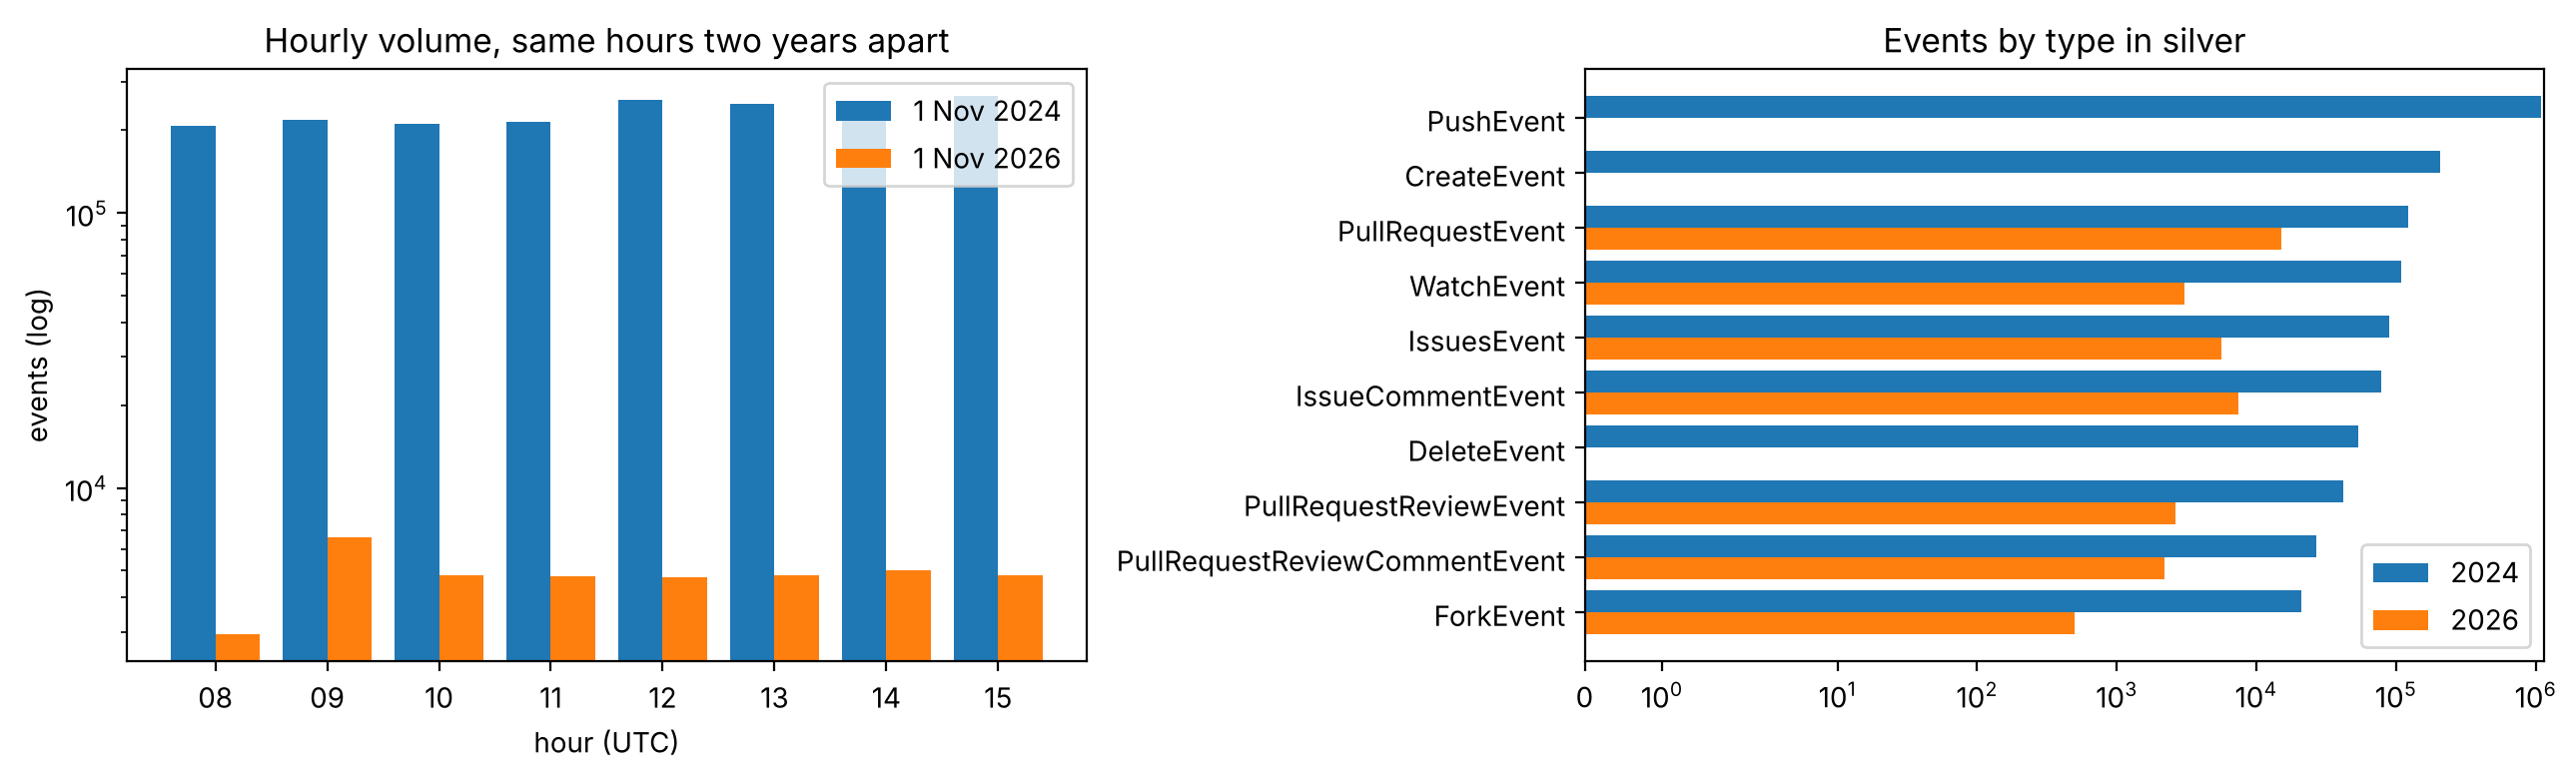

In [6]:
def profile_batch(paths):
    """Profile raw JSON lines (field presence, types, volume) without trusting the schema."""
    import collections
    types, pr_fields, push_size, n = collections.Counter(), collections.Counter(), 0, 0
    per_hour = []
    for p in paths:
        k = 0
        with gzip.open(p, "rt") as f:
            for line in f:
                e = json.loads(line); n += 1; k += 1
                types[e["type"]] += 1
                if e["type"] == "PullRequestEvent":
                    pr = (e.get("payload") or {}).get("pull_request") or {}
                    pr_fields["has_merged"] += "merged" in pr
                    pr_fields["has_additions"] += "additions" in pr
                    pr_fields["n"] += 1
        per_hour.append(k)
    return dict(n=n, per_hour=per_hour, types=types, pr_fields=pr_fields)


prof24, prof26 = profile_batch(files_2024), profile_batch(files_2026)
share24 = {t: c / prof24["n"] for t, c in prof24["types"].items()}
contract = dict(
    hourly_volume=(0.5 * np.min(prof24["per_hour"]), 2.0 * np.max(prof24["per_hour"])),
    required_types={t: 0.25 * s for t, s in share24.items() if s >= 0.01},
    pr_merged_present_min=0.95,
    allowed_types=set(prof24["types"]))


def check(prof):
    rows = []
    lo, hi = contract["hourly_volume"]
    for i, k in enumerate(prof["per_hour"]):
        rows.append(("volume", f"hour {i + 1}: {k:,} events", lo <= k <= hi, f"expected {lo:,.0f}-{hi:,.0f}"))
    for t, m in contract["required_types"].items():
        s = prof["types"].get(t, 0) / max(prof["n"], 1)
        rows.append(("required type", t, s >= m, f"share {s:.2%} (min {m:.2%})"))
    pr = prof["pr_fields"]
    rate = pr["has_merged"] / max(pr["n"], 1)
    rows.append(("payload field", "pull_request.merged present", rate >= contract["pr_merged_present_min"], f"{rate:.0%} of PR events"))
    rate_a = pr["has_additions"] / max(pr["n"], 1)
    rows.append(("payload field", "pull_request.additions present", rate_a >= contract["pr_merged_present_min"], f"{rate_a:.0%} of PR events"))
    new = sorted(set(prof["types"]) - contract["allowed_types"])
    rows.append(("closed type list", "no unknown event types", not new, ", ".join(new) if new else "none"))
    return pd.DataFrame(rows, columns=["check", "item", "pass", "detail"])


rep24, rep26 = check(prof24), check(prof26)
print(f"2024 batch: {rep24['pass'].mean():.0%} of {len(rep24)} checks pass")
print(f"2026 batch: {rep26['pass'].mean():.0%} of {len(rep26)} checks pass")
display(rep26[~rep26["pass"]].reset_index(drop=True))

GOLD_DEPENDS = {"hourly_activity": ["volume"], "repo_activity": ["required type", "payload field"], "bot_share": []}
failed = set(rep26.loc[~rep26["pass"], "check"])
decision = {g: ("hold back" if set(deps) & failed else "publish") for g, deps in GOLD_DEPENDS.items()}
print("publication decision for the 2026 batch:", decision)

# the 2026 batch still lands in bronze and silver (raw truth is kept), but only safe gold tables are refreshed
to_bronze(files_2026)
parts_2026 = [(f"{t:%Y-%m-%d}", t.hour) for t in BATCH_2026]
to_silver(parts_2026); mark("bronze", parts_2026); mark("silver", parts_2026)
publish = [g for g, d in decision.items() if d == "publish"]
to_gold(["2026-11-01"], publish)
for g in set(GOLD_TABLES) - set(publish):  # a held-back table must not keep a stale partition from an earlier run
    shutil.rmtree(ROOT / "gold" / g / "dt=2026-11-01", ignore_errors=True)
print("gold refreshed for 2026:", publish, "| held back:", sorted(set(GOLD_TABLES) - set(publish)))
s_all = spark.read.parquet(str(ROOT / "silver"))
cmp = (s_all.groupBy(F.col("dt").cast("string").alias("dt"), "type").count().toPandas().pivot(index="type", columns="dt", values="count").fillna(0).astype(int)
       .sort_values("2024-11-01", ascending=False))
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(8)
ax[0].bar(x - 0.2, prof24["per_hour"], 0.4, label="1 Nov 2024"); ax[0].bar(x + 0.2, prof26["per_hour"], 0.4, label="1 Nov 2026")
ax[0].set_yscale("log"); ax[0].set_xticks(x); ax[0].set_xticklabels([f"{h:02d}" for h in range(8, 16)])
ax[0].set_xlabel("hour (UTC)"); ax[0].set_ylabel("events (log)"); ax[0].set_title("Hourly volume, same hours two years apart"); ax[0].legend()
top = cmp.head(10)
y = np.arange(len(top))
ax[1].barh(y - 0.2, top["2024-11-01"], 0.4, label="2024"); ax[1].barh(y + 0.2, top.get("2026-11-01", 0), 0.4, label="2026")
ax[1].set_yticks(y); ax[1].set_yticklabels(top.index); ax[1].set_xscale("symlog"); ax[1].invert_yaxis()
ax[1].set_title("Events by type in silver"); ax[1].legend()
plt.tight_layout(); fig.savefig(FIG / "upstream_change.png", dpi=130); plt.show()

## What the optimisations buy

Each query runs twice and the second (warm) time is reported. The machine is small, so absolute times matter less than the ratios.

In [7]:
def timed(fn, reps=2):
    best = None
    for _ in range(reps):
        t0 = time.time(); fn(); dt = time.time() - t0
        best = dt if best is None else min(best, dt)
    return best


raw_json = [str(p) for p in files_2024]
q_json = lambda: spark.read.schema(SCHEMA).json(raw_json).groupBy("type").count().collect()
q_bronze = lambda: spark.read.parquet(str(ROOT / "bronze")).filter("dt = '2024-11-01'").groupBy("type").count().collect()
q_all_hours = lambda: spark.read.parquet(str(ROOT / "silver")).filter("dt = '2024-11-01'").agg(F.countDistinct("repo_id")).collect()
q_one_hour = lambda: spark.read.parquet(str(ROOT / "silver")).filter("dt = '2024-11-01' AND hr = 12").agg(F.countDistinct("repo_id")).collect()

dim = spark.createDataFrame(pd.DataFrame({"type": KNOWN_TYPES, "category": ["code"] * 3 + ["review"] * 3 + ["issues"] * 2 + ["social"] * 2 + ["other"] * 5}))
s24 = spark.read.parquet(str(ROOT / "silver")).filter("dt = '2024-11-01'")
q_broadcast = lambda: s24.join(F.broadcast(dim), "type").groupBy("category").count().collect()


def q_shuffle():
    spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1"); spark.conf.set("spark.sql.adaptive.enabled", "false")
    try:
        s24.join(dim.hint("merge"), "type").groupBy("category").count().collect()
    finally:
        spark.conf.set("spark.sql.autoBroadcastJoinThreshold", str(10 * 2**20)); spark.conf.set("spark.sql.adaptive.enabled", "true")


perf = pd.DataFrame([
    ("count by type", "gzip JSON (raw)", timed(q_json, 1)),
    ("count by type", "Parquet (bronze)", timed(q_bronze)),
    ("distinct repos", "all 8 hour-partitions", timed(q_all_hours)),
    ("distinct repos", "1 partition (pruned)", timed(q_one_hour)),
    ("join with type dimension", "broadcast hash join", timed(q_broadcast)),
    ("join with type dimension", "sort-merge join (shuffle)", timed(q_shuffle)),
], columns=["query", "variant", "seconds"])
display(perf.round(2))

# same gold query on three engines: top repos by stars on 1 Nov 2024 from the silver Parquet
silver_glob = str(ROOT / "silver" / "dt=2024-11-01" / "*" / "*.parquet")
eng = []
eng.append(("Spark (local, 2 cores)", timed(lambda: spark.read.parquet(str(ROOT / "silver")).filter("dt = '2024-11-01' AND type = 'WatchEvent'")
                                             .groupBy("repo_name").count().orderBy(F.desc("count")).limit(20).collect())))
eng.append(("DuckDB", timed(lambda: duckdb.sql(f"SELECT repo_name, COUNT(*) c FROM read_parquet('{silver_glob}') WHERE type = 'WatchEvent' "
                                               "GROUP BY 1 ORDER BY c DESC LIMIT 20").fetchall())))
eng.append(("Polars (lazy)", timed(lambda: pl.scan_parquet(silver_glob).filter(pl.col("type") == "WatchEvent").group_by("repo_name")
                                   .len().sort("len", descending=True).head(20).collect())))
eng = pd.DataFrame(eng, columns=["engine", "seconds"])
display(eng.round(3))

,query,variant,seconds
0,count by type,gzip JSON (raw),7.42
1,count by type,Parquet (bronze),0.29
2,distinct repos,all 8 hour-partitions,0.69
3,distinct repos,1 partition (pruned),0.28
4,join with type dimension,broadcast hash join,0.53
5,join with type dimension,sort-merge join (shuffle),0.80


,engine,seconds
0,"Spark (local, 2 cores)",0.446
1,DuckDB,0.045
2,Polars (lazy),0.039


## Findings

In [8]:
from IPython.display import Markdown
P = perf.set_index(["query", "variant"]).seconds
md = "\n\n".join([
    f"**Pipeline.** The 2024 batch (8 hourly files, {mb(files_2024):.0f} MB gzip) produced {n_bronze:,} bronze rows and {n_silver:,} silver rows "
    f"({n_quar:,} quarantined). Re-running the batch left the counts unchanged ({'idempotent' if before == after else 'not idempotent'}).",
    f"**Upstream change.** The same eight hours in 2026 hold {prof26['n']:,} events against {prof24['n']:,} in 2024 ({prof26['n'] / prof24['n'] - 1:+.1%}). "
    f"{int((~rep26['pass']).sum())} of {len(rep26)} contract checks fail: " + "; ".join(f"{r.item} ({r.detail})" for r in rep26[~rep26['pass']].itertuples() if r.check != 'volume')
    + f". All {int((rep26.check == 'volume').sum())} hourly volume checks fail. Decision: " + ", ".join(f"{k}: {v}" for k, v in decision.items()) + ".",
    f"**Optimisations.** Counting by type took {P[('count by type', 'gzip JSON (raw)')]:.1f} s on raw JSON and {P[('count by type', 'Parquet (bronze)')]:.2f} s on Parquet "
    f"({P[('count by type', 'gzip JSON (raw)')] / P[('count by type', 'Parquet (bronze)')]:.0f}x). Partition pruning cut a distinct-count from "
    f"{P[('distinct repos', 'all 8 hour-partitions')]:.2f} s to {P[('distinct repos', '1 partition (pruned)')]:.2f} s; the broadcast join ran in "
    f"{P[('join with type dimension', 'broadcast hash join')]:.2f} s against {P[('join with type dimension', 'sort-merge join (shuffle)')]:.2f} s with a shuffle.",
    "**Engines.** On the same gold query over the silver Parquet: " + ", ".join(f"{r.engine} {r.seconds:.2f} s" for r in eng.itertuples())
    + ". At this size a single-node engine is faster; Spark earns its overhead when data or concurrency outgrow one machine.",
])
(OUT / "findings.md").write_text(md)
json.dump(dict(bronze_rows=n_bronze, silver_rows=n_silver, quarantine_rows=n_quar, idempotent=before == after,
               events_2024=prof24["n"], events_2026=prof26["n"], failed_checks=rep26[~rep26["pass"]].to_dict("records"),
               decision=decision, perf=perf.to_dict("records"), engines=eng.to_dict("records")),
          open(OUT / "summary.json", "w"), indent=2, default=str)
display(Markdown(md))
spark.stop()

**Pipeline.** The 2024 batch (8 hourly files, 786 MB gzip) produced 1,870,675 bronze rows and 1,870,675 silver rows (0 quarantined). Re-running the batch left the counts unchanged (idempotent).

**Upstream change.** The same eight hours in 2026 hold 38,471 events against 1,870,675 in 2024 (-97.9%). 14 of 21 contract checks fail: CreateEvent (share 0.00% (min 2.76%)); PushEvent (share 0.00% (min 14.67%)); DeleteEvent (share 0.00% (min 0.72%)); pull_request.merged present (0% of PR events); pull_request.additions present (0% of PR events); no unknown event types (DiscussionEvent). All 8 hourly volume checks fail. Decision: hourly_activity: hold back, repo_activity: hold back, bot_share: publish.

**Optimisations.** Counting by type took 7.4 s on raw JSON and 0.29 s on Parquet (25x). Partition pruning cut a distinct-count from 0.69 s to 0.28 s; the broadcast join ran in 0.53 s against 0.80 s with a shuffle.

**Engines.** On the same gold query over the silver Parquet: Spark (local, 2 cores) 0.45 s, DuckDB 0.05 s, Polars (lazy) 0.04 s. At this size a single-node engine is faster; Spark earns its overhead when data or concurrency outgrow one machine.

### Limitations

* Eight hours per batch on a 2-core machine; the code is written for a cluster (partitioned writes, no driver-side collection of data), but the timings are single-node.
* The contract is learned from one batch; in production it would be learned from weeks of history, with seasonality in the volume band.
* The reasons behind the change in the public event stream are outside the scope of this notebook; the point is that the pipeline notices.

An Airflow DAG that runs the same steps every hour is in `dags/gharchive_hourly.py`.

**Data:** GH Archive (Ilya Grigorik), https://www.gharchive.org, licensed under the MIT license.